# Week (1) Module C: Fundamentals of Probability
**Course:** Statistics and Machine Learning

---

### Module Contributor(s)
| Full Name | Role |
|---|---|
| `_______________` | `_______________` |
| `_______________` | `_______________` |

---

### About this Module
This module covers **Tasks 6 and 7** of the Week (1) practical.
Your outputs will be merged with **Modules A, B, and D into the group's final notebook**.

**Background: Day 2 lecture recap:**

Probability is the mathematical language of uncertainty. The probability of an event is the ratio of favourable outcomes to total possible outcomes, and always lies between 0 (impossible) and 1 (certain). 

> Two core rules connect probabilities of multiple events:
- **Addition Rule:** P(A ∪ B) = P(A) + P(B) − P(A ∩ B) —> used when asking "A *or* B?"
- **Multiplication Rule (independent):** P(A ∩ B) = P(A) × P(B) —> used when asking "A *and* B?" for unrelated events
- **Multiplication Rule (dependent):** P(A ∩ B) = P(A) × P(B | A) —> used when the outcome of A changes the probability of B

**Dataset:** Pima Indians Diabetes —> DOI: https://www.openml.org/d/37

---
> Cells marked `# TODO` require code. Cells marked `✍️` require a written response.

---
# Task 6: Empirical Probability from Real Data

The simplest way to estimate probability from data is to count: how many rows satisfy a condition, divided by the total number of rows. This is called an **empirical probability**.

> **Goal:** Compute and interpret empirical probabilities from the dataset, and connect them to the addition and multiplication rules.

In [ ]:
# ── Task 6 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (9, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# Clinical thresholds defined here so every cell in Task 6 uses the same values.
# Changing them here propagates everywhere — no need to edit multiple cells.
# 140 mg/dL: WHO/ADA threshold for impaired glucose tolerance.
HIGH_GLUCOSE_THRESHOLD = 140   # mg/dL
# 30 kg/m²: WHO threshold separating 'overweight' from 'obese'.
HIGH_BMI_THRESHOLD     = 30    # kg/m²

n = len(df)  # total number of patients — used as the denominator in probability calculations
print(f'Dataset loaded: {n} patients')
print(f'Clinical thresholds: Glucose > {HIGH_GLUCOSE_THRESHOLD}, BMI > {HIGH_BMI_THRESHOLD}')


In [ ]:
# Provided: compute the base-rate (unconditional) probability of diabetes

# Key insight: when a column contains only 0s and 1s, its mean equals
# the proportion of 1s. This is because:
#   mean = (sum of all values) / n = (count of 1s * 1 + count of 0s * 0) / n
#        = count of 1s / n = P(Outcome = 1) = P(Diabetic)
# This is the cleanest one-liner for computing a binary proportion in pandas.
p_diabetic = df['Outcome'].mean()
p_non_diabetic = 1 - p_diabetic  # probabilities must sum to 1 for exhaustive outcomes

print(f'P(Diabetic)     = {p_diabetic:.4f}  ({p_diabetic*100:.1f}%)')
print(f'P(Non-Diabetic) = {p_non_diabetic:.4f}  ({p_non_diabetic*100:.1f}%)')


In [ ]:
# TODO: Compute the following empirical probabilities from the dataset.
# Print each result clearly labelled, rounded to 4 decimal places.
#
#   P(A) = probability that a randomly chosen patient has Glucose > 140
#   P(B) = probability that a randomly chosen patient has BMI > 30
#
# Hint: (df['Glucose'] > HIGH_GLUCOSE_THRESHOLD).mean()

# YOUR CODE HERE


In [ ]:
# TODO: Apply the Addition Rule to find P(A ∪ B):
# the probability that a patient has HIGH Glucose OR HIGH BMI (or both).
#
# Step 1: Compute P(A ∩ B) — patient has BOTH high Glucose AND high BMI.
# Step 2: Apply P(A ∪ B) = P(A) + P(B) − P(A ∩ B)
# Step 3: Verify by directly counting rows where EITHER condition is true.
#         Both values should match.
#
# Print: P(A), P(B), P(A ∩ B), P(A ∪ B) [formula], P(A ∪ B) [direct count]

# YOUR CODE HERE


In [ ]:
# TODO: Apply the Multiplication Rule for INDEPENDENT events.
#
# Scenario: Two patients are selected independently (with replacement).
# Q: What is the probability that BOTH have high Glucose (> 140)?
#
# Step 1: Use P(both high glucose) = P(A) × P(A)  [independent → same probability each draw]
# Step 2: Print the result.
# Step 3: Interpret: is this event common or rare?

# YOUR CODE HERE


In [ ]:
# TODO: Compute the CONDITIONAL probability P(Diabetic | High Glucose):
# Given that a patient has Glucose > 140, what is the probability they are Diabetic?
#
# Step 1: Filter df to only rows where Glucose > HIGH_GLUCOSE_THRESHOLD.
# Step 2: Among those rows, compute the proportion who are Diabetic (Outcome == 1).
# Step 3: Compare with the unconditional P(Diabetic) computed above.
#
# Print both probabilities side by side with a brief comment.

# YOUR CODE HERE


In [ ]:
# TODO: Create a grouped bar chart comparing:
#   P(Diabetic | High Glucose)  vs  P(Diabetic | Normal Glucose)
#   P(Diabetic | High BMI)      vs  P(Diabetic | Normal BMI)
#
# Present as two side-by-side bar pairs.
# Hint: compute each conditional probability first, then build a small DataFrame and use df.plot(kind='bar').
# Add value labels above each bar.

# YOUR CODE HERE


### ✍️ Interpretation: Task 6

1. You computed P(A ∪ B) into two ways using the formula and by direct counting. Did they match? Why must they always agree mathematically?
2. P(Diabetic | High Glucose) vs P(Diabetic): is high glucose a strong signal for diabetes in this data? By how much does it shift the probability?
3. In the addition rule, we subtract P(A ∩ B). What would happen to the result if we forgot to subtract it? Give a concrete example using your numbers.

> *Your answer here:*

---
# Task 7: Probability Rules: Simulation vs Formula

A powerful way to build intuition for probability rules is to **simulate** the process many times and compare the simulated proportion with the analytical formula.

> **Goal:** Verify probability rules by simulation. Understand the difference between independent and dependent events, and how sample size affects empirical estimates.

In [1]:
# ── Task 7 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Setting the global random seed ensures that every student gets the same
# simulation results, making comparison and grading consistent.
# Without this, np.random.choice() produces different draws each run.
np.random.seed(42)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# Re-declare the threshold here so Task 7 is self-contained and can run
# even if the student hasn't run Task 6 yet.
HIGH_GLUCOSE_THRESHOLD = 140
n = len(df)
print('Ready')


Ready


In [2]:
# TODO: Simulate the independent multiplication rule.
#
# Scenario: Draw two patients WITH REPLACEMENT.
#           What fraction of draws result in BOTH patients having high Glucose?
#
# Step 1: Compute p_high = empirical P(Glucose > 140) from the dataset.
# Step 2: Run 10,000 simulated draws of 2 patients (with replacement).
#         Use: np.random.choice(df['Glucose'].values, size=(10_000, 2), replace=True)
# Step 3: Count how many rows have BOTH values > HIGH_GLUCOSE_THRESHOLD.
# Step 4: Compare simulated proportion vs formula: p_high * p_high
#
# Print: analytical result, simulated result, absolute difference.

np.random.seed(42)

# YOUR CODE HERE
p_high = (df['Glucose'] > HIGH_GLUCOSE_THRESHOLD).mean()
simulated=np.random.choice(df['Glucose'].values, size=(10_000, 2), replace=True)
count_values=np.all(simulated > HIGH_GLUCOSE_THRESHOLD, axis=1)
summing=count_values.sum()
simulated_proportion=count_values.mean()
compare=p_high*p_high
print(f"Analytical result: {compare}")
print(f"Simulated result: {simulated_proportion}")
print(f"Absolute difference: {abs(compare - simulated_proportion)}")

Analytical result: 0.0625
Simulated result: 0.0636
Absolute difference: 0.0011000000000000038


In [ ]:
# TODO: Simulate the dependent multiplication rule.
#
# Scenario: Draw two patients WITHOUT REPLACEMENT.
#           What fraction of draws result in BOTH patients being Diabetic?
#
# Step 1: Compute p_first = P(first patient is Diabetic) from dataset.
# Step 2: Compute p_second_given_first = P(second is Diabetic | first was Diabetic)
#         After removing one Diabetic patient, how many remain?
# Step 3: Analytical result = p_first × p_second_given_first
# Step 4: Simulate 10,000 draws of 2 patients WITHOUT replacement.
#         Use: np.random.choice(df['Outcome'].values, size=2, replace=False) in a loop
#         OR: use np.apply_along_axis on a matrix of shuffled indices.
#         Simpler approach: just loop 10,000 times with np.random.choice(..., replace=False)
# Step 5: Compare simulated vs analytical.

np.random.seed(42)

# YOUR CODE HERE
Compute_p_first=(df['Outcome']==1).mean()
num_diabetic=(df['Outcome']==1).sum()
num_total=len(df)
Compute_p_second_given_first=(num_diabetic-1)/(num_total-1)
analytical_result=Compute_p_first*Compute_p_second_given_first
simulte=np.array([np.random.choice(df['Outcome'].values, size=2, replace=False) for i in range(10_000)])
count_diabetic=np.all(simulte==1, axis=1)
simulated_result=count_diabetic.mean()
print(f"Analytical result: {analytical_result}")
print(f"Simulated result: {simulated_result}")
print(f"Absolute difference: {abs(analytical_result - simulated_result)}")


Analytical result: 0.12147571707953063
Simulated result: 0.1264
Absolute difference: 0.004924282920469383


Text(0.5, 1.0, 'Simulation Accuracy Improves with More Trials')

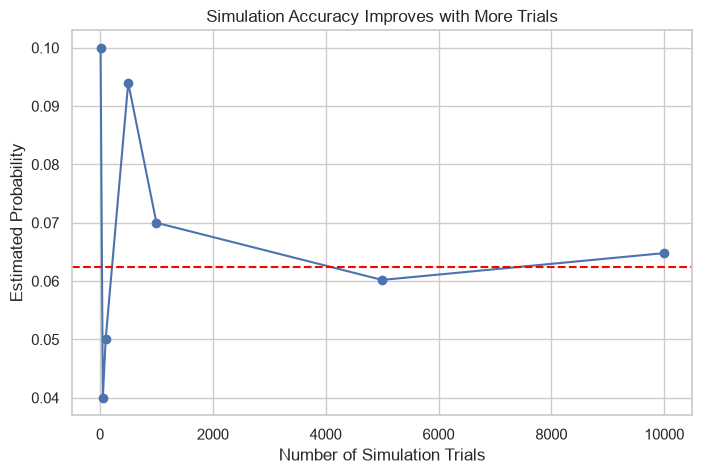

In [8]:
# TODO: Show how simulation accuracy improves with more trials.
#
# For the independent case (both patients have Glucose > 140):
# Compute the simulated probability using N = 10, 50, 100, 500, 1000, 5000, 10000 trials.
# Plot the simulated probability vs N as a line chart.
# Add a horizontal dashed line showing the true analytical probability.
#
# Label axes: x = 'Number of Simulation Trials', y = 'Estimated Probability'

np.random.seed(42)

# p_high: the true empirical probability of a patient having Glucose > 140.
# Used as the analytical reference line in your convergence plot.
p_high = (df['Glucose'] > HIGH_GLUCOSE_THRESHOLD).mean()

# true_prob: the analytical answer for P(both patients have high Glucose)
# under the independence assumption: P(A) * P(A) = p_high^2.
true_prob = p_high ** 2

# trial_sizes: the x-axis values for your convergence plot.
# Notice the spacing: small values (10, 50) show high variability;
# large values (5000, 10000) converge close to true_prob.
trial_sizes = [10, 50, 100, 500, 1000, 5000, 10000]

# YOUR CODE HERE
probs=[]
for i in trial_sizes:
    simulated=np.random.choice(df['Glucose'].values, size=(i, 2), replace=True)
    count_values=np.all(simulated > HIGH_GLUCOSE_THRESHOLD, axis=1)
    simulated_proportion=count_values.mean()
    probs.append(simulated_proportion)

plt.figure(figsize=(8,5))

plt.plot(trial_sizes, probs, marker='o', label='Simulated Probability')

plt.axhline(
    y=true_prob,
    color='red',
    linestyle='--',
    label='True Analytical Probability'
)

plt.xlabel('Number of Simulation Trials')
plt.ylabel('Estimated Probability')

plt.title('Simulation Accuracy Improves with More Trials')


### ✍️ Interpretation: Task 7

1. For the independent simulation: how close was your simulated proportion to the analytical formula result? What does the convergence plot tell you about the relationship between number of trials and accuracy?
2. For the dependent simulation: how different is the analytical answer from the independent case? Why does removing one patient (without replacement) change the probability, and by roughly how much?
3. In a real clinical study of 768 patients, would you treat repeated sampling as independent or dependent? Does it matter given the dataset size? Explain.

> *Your answer here:*
1- The simulated proportion was very close to the analytic result,the differnce is due to rndom variation
the plot shows thats as the number of trials increase ,the simulated propbabilty becomes aaccurate
2-The dependent result is slightly lower thn the independent result becuase removing the one diabetic chnges the probabilty of the second patient being diabetic
the differnce is small
3-In a real clinical study of 768 patients, sampling would usually be treated as dependent without replacement because a patient cannot be selected twice.
However, with a large dataset the difference is very small, so the independent assumption often gives a very close approximation.

---
## 📋 Module C: Handoff Summary

| Item | Your finding |
|---|---|
| P(Diabetic) in this dataset | ??? |
| P(Glucose > 140) | ??? |
| P(BMI > 30) | ??? |
| P(Glucose > 140 OR BMI > 30) | ??? |
| P(Diabetic \| High Glucose) | ??? |
| Lift over base rate (conditional / unconditional) | ???× |
| Key insight to share with the group | ??? |

> Fill in the table above before merging with the group.